# Universe State — Trend (descriptive)

A fast read of **where each instrument sits right now**, not a forecast. Every descriptor is causal (trailing-window) and comparable across instruments:
- **trend score** = direction × intensity (vol-normalized, Baz-shaped EWMAC ladder);
- **intensity %ile** = how strong that trend is *vs the instrument's own history*;
- **scale agreement** = fraction of fast→slow scales pointing the same way;
- **efficiency ratio** = trendiness vs chop; **slope-t** = regression-slope significance; **regime** ∈ {up_trend, down_trend, chop}.

> Descriptive — *state characterization, not tradeability.* No forward returns are used. Predictive validation (IC/CV/DSR) lives separately in `src/signals/eval`.

In [1]:
import sys
sys.path[:0] = ['C:\\Users\\SamuelAhou\\Documents\\operator']
import warnings
warnings.filterwarnings('ignore')
import pandas as pd
from research.state import scan_lib as S
from research.trend import descriptive_lib as D
scan, series = S.build_scan()
prices = {s['label']: S.load_price(s) for s in S.UNIVERSE}
print(f'{len(scan)} instruments across {scan.sector.nunique()} sectors')

4 instruments across 2 sectors


## 0. Does the reported reading actually describe the regime? (cross-instrument)

The scan below reports one **causal trend reading** per instrument (the `mean_z` multi-scale aggregate, via `state.trend_state`). Before trusting it, we validate — across the *whole universe* — that it **describes the reference regime** (the centered hindsight label from the per-instrument studies). For each instrument: **direction agreement** (concurrent hit-rate on trending bars), **trend/chop AUC**, **lag** to a regime turn, and **flip-rate** (stability). Consistently high agreement + AUC > 0.5 means the single reading we surface is a faithful, comparable descriptor everywhere.

In [2]:
val = {}
for spec in S.UNIVERSE:
    pr = prices[spec['label']]
    if pr.dropna().empty:
        continue
    reg = D.reference_regime(pr)
    mz = D.aggregates(D.signal_panel(pr))[['mean_z']]
    val[spec['label']] = D.score_panel(mz, reg).loc['mean_z']
pd.DataFrame(val).T.round(3)

,dir_agreement,trendchop_auc,lag_bars,flip_rate
es1,0.881,0.649,9.0,0.027
nq1,0.876,0.671,7.0,0.028
btcusdt,0.842,0.635,7.0,0.019
ethusdt,0.814,0.594,7.0,0.026


## 1. Scan table
The whole universe at a glance — green = strong-up / high, red = strong-down / low. Sorted by sector then trend score.

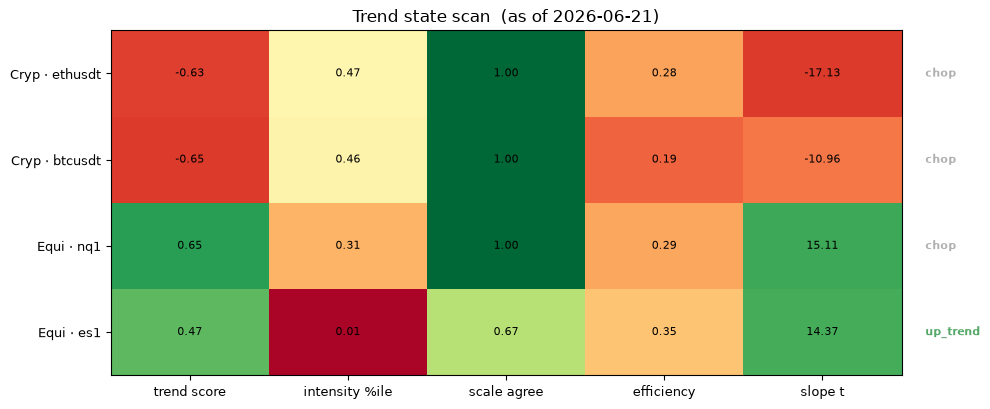

,label,sector,regime,score,intensity_pct,agree,er,slope_t,xs_rank
0,ethusdt,Crypto,chop,-0.63,0.47,1.00,0.28,-17.13,3
1,btcusdt,Crypto,chop,-0.65,0.46,1.00,0.19,-10.96,4
2,nq1,Equity Index,chop,0.65,0.31,1.00,0.29,15.11,1
3,es1,Equity Index,up_trend,0.47,0.01,0.67,0.35,14.37,2


In [3]:
S.plot_scan_table(scan)
scan[['label','sector','regime','score','intensity_pct','agree','er','slope_t','xs_rank']].round(2)

## 2. State map
Signed trend score (x) vs efficiency/trendiness (y); colour = regime, marker size = cross-scale agreement. Right & high = clean up-trend; near the x=0 line or below the dashed chop band = directionless / choppy.

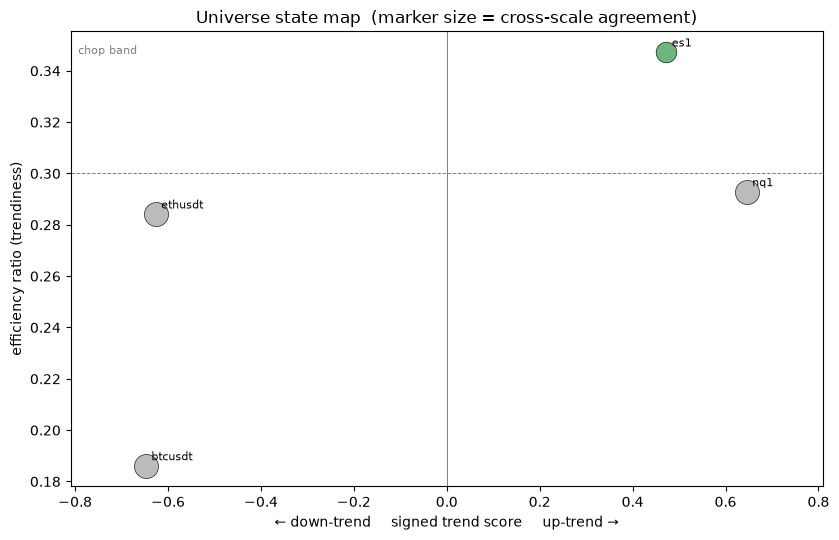

In [4]:
S.plot_state_map(scan)

## 3. Regime composition
How much of each sector is trending up / down / chopping right now.

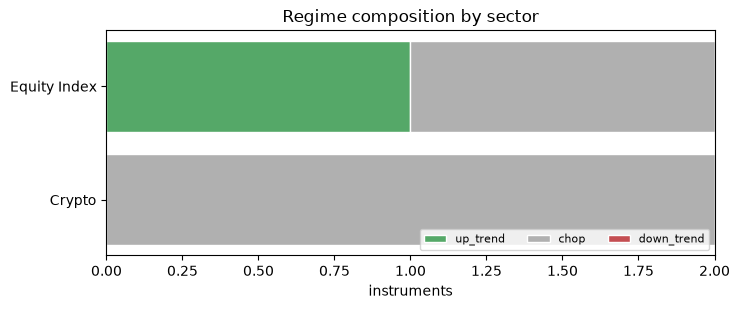

In [5]:
S.plot_regime_composition(scan)

## 4. State cards (drill-down)
Per instrument: price with regime shading, then the descriptor history (intensity & its percentile; efficiency & scale-agreement).

### Equity Index

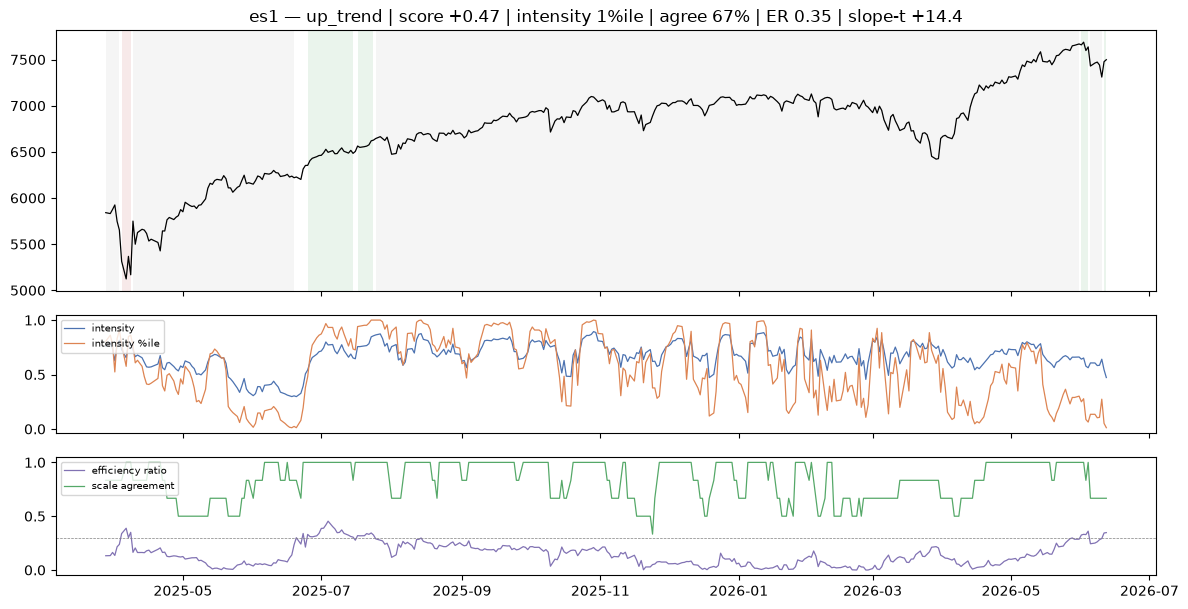

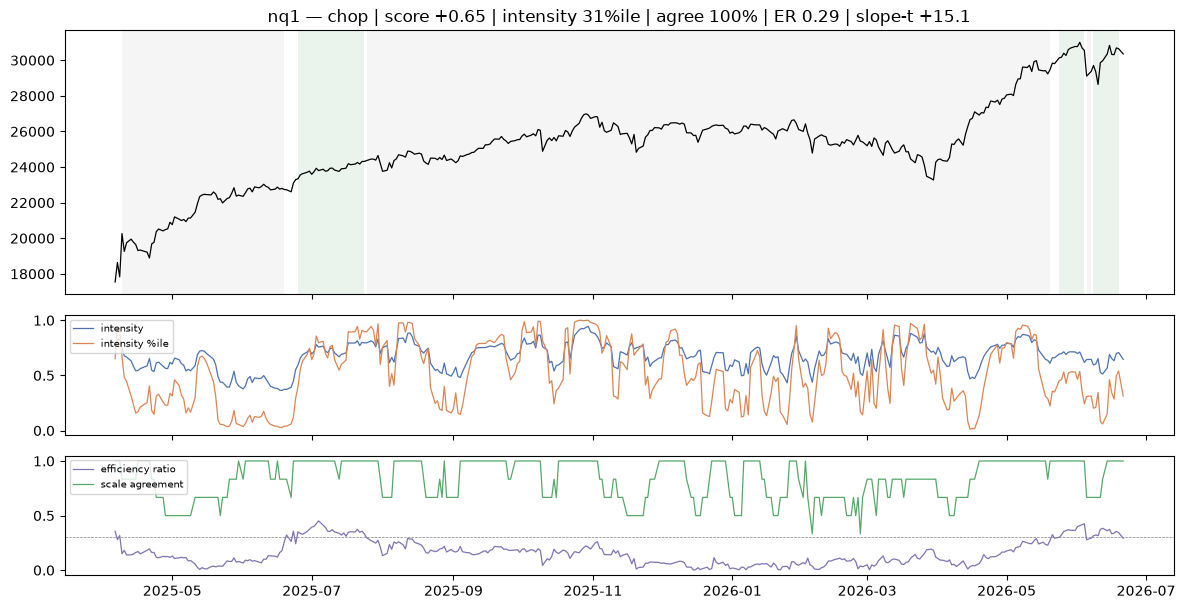

In [6]:
for lab in ['es1', 'nq1']:
    if lab in series:
        S.plot_state_card(lab, prices[lab], series[lab])

### Crypto

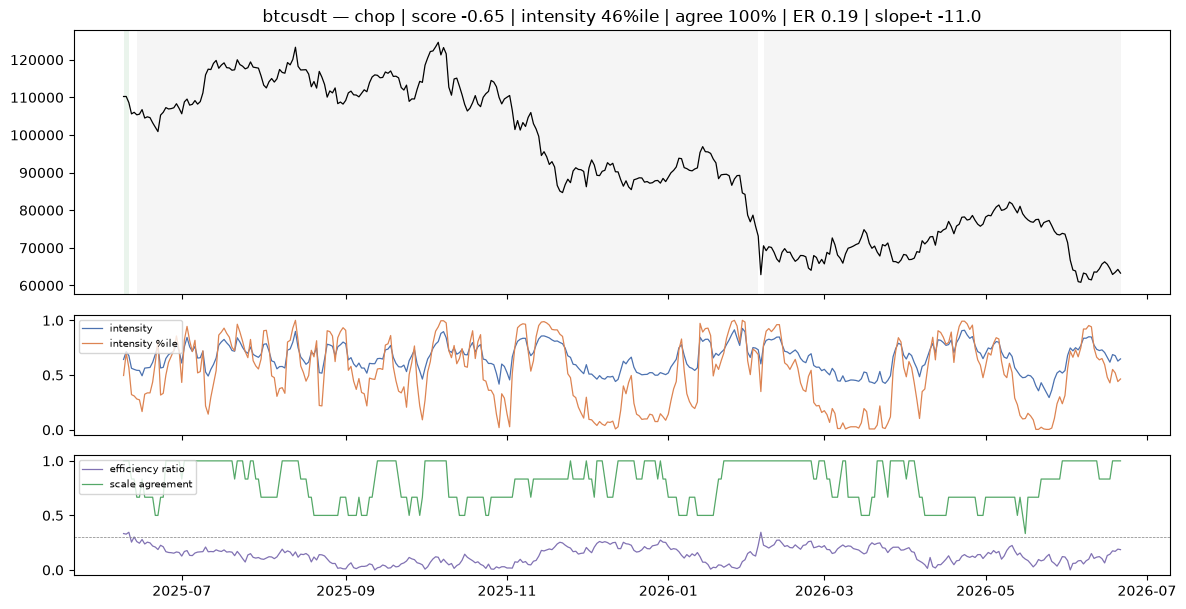

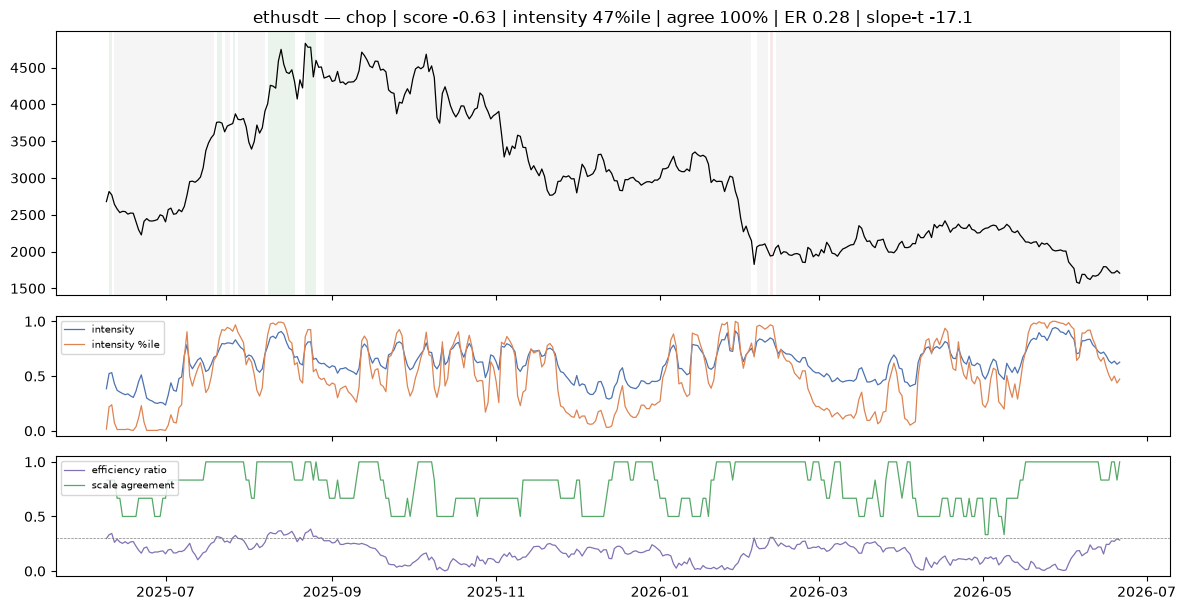

In [7]:
for lab in ['btcusdt', 'ethusdt']:
    if lab in series:
        S.plot_state_card(lab, prices[lab], series[lab])

## How to use this
Scan the table/map to triage the universe, then open a state card for context. *Next:* add the mean-reversion state (stretch from anchors, reverting-regime tags) and support/resistance state (distance to the nearest volume node / pivot) as parallel scans, then compose the per-sector dashboard.